In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os
from sklearn.linear_model import LinearRegression
import sys
import pyblock
bme_dir = '/projects/lindorff_group/people/thd711/HDX_project/code/BME/' # replace this with your local copy of the BME code
sys.path.append(bme_dir)
import BME as BME

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

outpath='./'
hyres_path = '../../MD_DATA/'
bioemu_path = '../../BIOEMU_IDPs/'
desres_path = '../../DESRES_IDPs/'
exp_data_path = '../../ORTHOGONAL_EXP_DATA/'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]



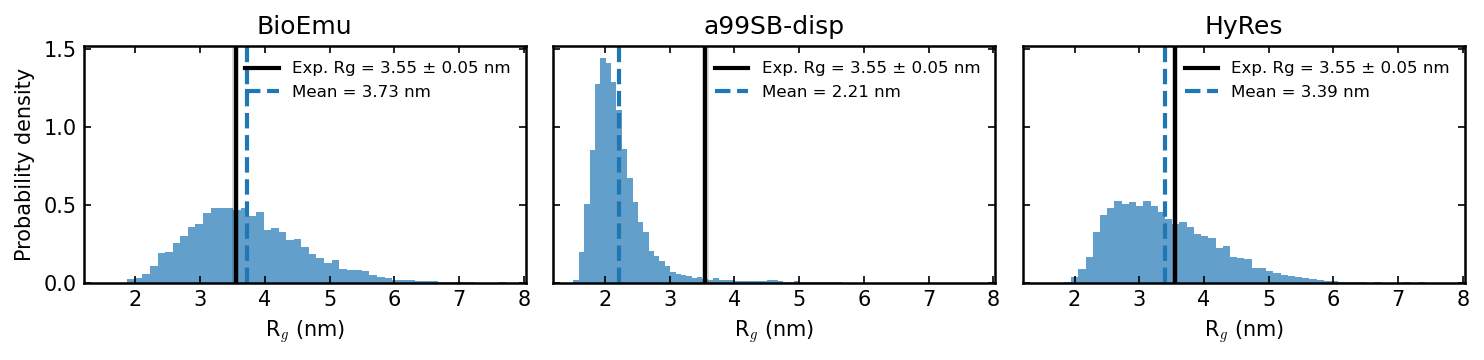

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# comparison with Rg (radius of gyration)
protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

# experimental Rg
exp_rg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/Rg.dat')
exp_rg_mean = exp_rg[0]
exp_rg_err  = exp_rg[1]

# load Rg for each ensemble
all_rg = []

for ensemble, path in zip(ensembles, ensemble_paths):

    traj_names = np.sort(find_xtc_filenames(path + f'./{protein}/'))

    rg = []
    for traj in traj_names:
        rg_file = path + f'./{protein}/rg_data/rg_{traj[:-4]}.txt'
        tmprg = np.loadtxt(rg_file)
        rg.append(np.asarray(tmprg).ravel())

    rg = np.concatenate(rg, axis=0)
    all_rg.append(rg)

# plot
fig, axes = plt.subplots(
    1, 3,
    figsize=(10., 2.5),
    sharex=True,
    sharey=True
)

for ax, ensemble, rg in zip(axes, ensembles, all_rg):

    rg_mean = np.mean(rg)

    ax.hist(
        rg,
        bins=50,
        density=True,
        color = 'tab:blue',
        alpha=0.7
    )

    # experimental uncertainty region
    ax.axvspan(
        exp_rg_mean - exp_rg_err,
        exp_rg_mean + exp_rg_err,
        color='k',
        alpha=0.15,
        linewidth=0
    )

    # experimental Rg
    ax.axvline(
        exp_rg_mean,
        color='k',
        linestyle='-',
        linewidth=2,
        label=f'Exp. Rg = {exp_rg_mean:.2f} ± {exp_rg_err:.2f} nm'
    )

    # ensemble mean Rg
    ax.axvline(
        rg_mean,
        linestyle='--',
        color = 'tab:blue',
        linewidth=2,
        label=f'Mean = {rg_mean:.2f} nm'
    )

    ax.set_title(ensemble)
    ax.set_xlabel('R$_g$ (nm)')
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel('Probability density')

plt.tight_layout()
plt.savefig('rg_distributions.png')
plt.show()

/tmp/ipykernel_1484116/727510941.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.4)


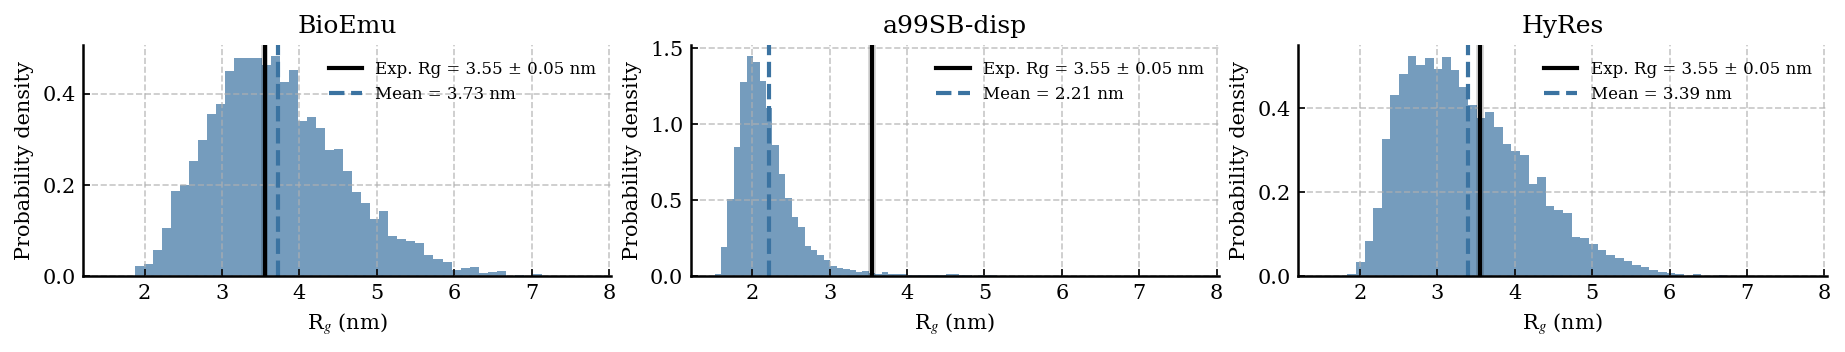

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# comparison with Rg (radius of gyration)

protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

COLOR3 = "#3B73A1"

# experimental Rg

exp_rg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/Rg.dat')
exp_rg_mean = exp_rg[0]
exp_rg_err = exp_rg[1]

# load Rg for each ensemble

all_rg = []

for ensemble, path in zip(ensembles, ensemble_paths):

    traj_names = np.sort(find_xtc_filenames(path + f'./{protein}/'))

    rg = []
    for traj in traj_names:
        rg_file = path + f'./{protein}/rg_data/rg_{traj[:-4]}.txt'
        tmprg = np.loadtxt(rg_file)
        rg.append(np.asarray(tmprg).ravel())

    rg = np.concatenate(rg, axis=0)
    all_rg.append(rg)

# plot

fig, axes = plt.subplots(1, 3, figsize=(15, 2.), sharex=True, sharey=False, gridspec_kw={'wspace': 0.15})

for ax, ensemble, rg in zip(axes, ensembles, all_rg):

    rg_mean = np.mean(rg)

    ax.hist(rg, bins=50, density=True, color=COLOR3, alpha=0.7)

    # experimental uncertainty region
    ax.axvspan(exp_rg_mean - exp_rg_err, exp_rg_mean + exp_rg_err, color='k', alpha=0.15, linewidth=0)

    # experimental Rg
    ax.axvline(exp_rg_mean, color='k', linestyle='-', linewidth=2, label=f'Exp. Rg = {exp_rg_mean:.2f} ± {exp_rg_err:.2f} nm')

    # ensemble mean Rg
    ax.axvline(rg_mean, linestyle='--', color=COLOR3, linewidth=2, label=f'Mean = {rg_mean:.2f} nm')

    ax.set_title(ensemble)
    ax.set_xlabel('R$_g$ (nm)')
    ax.set_ylabel('Probability density')
    ax.legend(frameon=False, fontsize=8)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False, labelleft=True)

plt.tight_layout(pad=0.4)
plt.savefig('rg_distributions.pdf', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2103170/249645437.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.4)


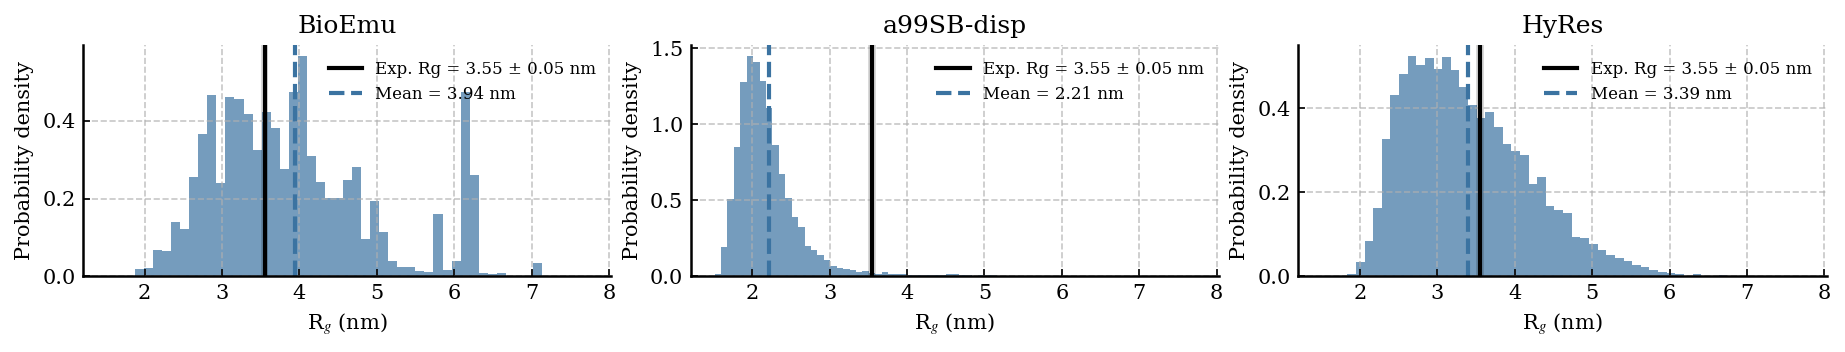

In [3]:
# now with BioEmu posterior 2 weights from HDXMS reweighting

import numpy as np
import matplotlib.pyplot as plt

# comparison with Rg (radius of gyration)

protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

COLOR3 = "#3B73A1"

# experimental Rg

exp_rg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/Rg.dat')
exp_rg_mean = exp_rg[0]
exp_rg_err = exp_rg[1]

# load Rg for each ensemble

all_rg = []

for ensemble, path in zip(ensembles, ensemble_paths):

    traj_names = np.sort(find_xtc_filenames(path + f'./{protein}/'))

    rg = []
    for traj in traj_names:
        try:
            okframes = np.loadtxt(path + f'./{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt', dtype=int)
        except:
            okframes = np.arange(md.load(path + f'./{protein}/{traj}',top=path + f'./{protein}/protein.pdb').n_frames)
        rg_file = path + f'./{protein}/rg_data/rg_{traj[:-4]}.txt'
        tmprg = np.loadtxt(rg_file)[okframes]
        rg.append(np.asarray(tmprg).ravel())

    rg = np.concatenate(rg, axis=0)
    all_rg.append(rg)

# plot

fig, axes = plt.subplots(1, 3, figsize=(15, 2.), sharex=True, sharey=False, gridspec_kw={'wspace': 0.15})

for ax, ensemble, rg in zip(axes, ensembles, all_rg):

    if ensemble=='BioEmu':
        phis = np.loadtxt(bioemu_path + f'./{protein}/HDXrew_M14DH_scaled/phis.txt')
        stop_idx= np.where(phis<0.1)[0][0]
        wopt_array = np.load(bioemu_path + f'./{protein}/HDXrew_M14DH_scaled/wopt_array.npy')[:stop_idx]
        prior_weights = wopt_array[-1] # posterior 2
    else:
        prior_weights = np.ones(rg.shape[0]) / rg.shape[0]

    rg_mean = np.average(rg, weights=prior_weights)

    ax.hist(rg, bins=50, density=True, color=COLOR3, alpha=0.7, weights=prior_weights)

    # experimental uncertainty region
    ax.axvspan(exp_rg_mean - exp_rg_err, exp_rg_mean + exp_rg_err, color='k', alpha=0.15, linewidth=0)

    # experimental Rg
    ax.axvline(exp_rg_mean, color='k', linestyle='-', linewidth=2, label=f'Exp. Rg = {exp_rg_mean:.2f} ± {exp_rg_err:.2f} nm')

    # ensemble mean Rg
    ax.axvline(rg_mean, linestyle='--', color=COLOR3, linewidth=2, label=f'Mean = {rg_mean:.2f} nm')

    ax.set_title(ensemble)
    ax.set_xlabel('R$_g$ (nm)')
    ax.set_ylabel('Probability density')
    ax.legend(frameon=False, fontsize=8)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False, labelleft=True)

plt.tight_layout(pad=0.4)
plt.savefig('rg_distributions_BioEmu_posterior2.pdf', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2162648/3727886736.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.4)


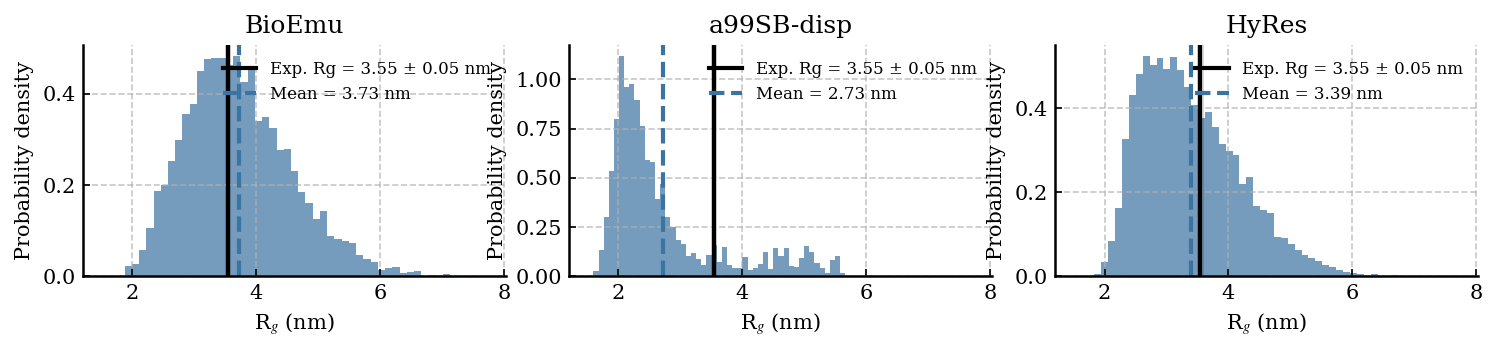

In [3]:
# now with DESRES posterior 2 weights from HDXMS reweighting

import numpy as np
import matplotlib.pyplot as plt

# comparison with Rg (radius of gyration)

protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

COLOR3 = "#3B73A1"

# experimental Rg

exp_rg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/Rg.dat')
exp_rg_mean = exp_rg[0]
exp_rg_err = exp_rg[1]

# load Rg for each ensemble

all_rg = []

for ensemble, path in zip(ensembles, ensemble_paths):

    traj_names = np.sort(find_xtc_filenames(path + f'./{protein}/'))

    rg = []
    for traj in traj_names:
        try:
            okframes = np.loadtxt(path + f'./{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt', dtype=int)
        except:
            okframes = np.arange(md.load(path + f'./{protein}/{traj}',top=path + f'./{protein}/protein.pdb').n_frames)
        rg_file = path + f'./{protein}/rg_data/rg_{traj[:-4]}.txt'
        tmprg = np.loadtxt(rg_file)[okframes]
        rg.append(np.asarray(tmprg).ravel())

    rg = np.concatenate(rg, axis=0)
    all_rg.append(rg)

# plot

fig, axes = plt.subplots(1, 3, figsize=(12, 2.), sharex=True, sharey=False, gridspec_kw={'wspace': 0.15})

for ax, ensemble, rg in zip(axes, ensembles, all_rg):

    if ensemble=='a99SB-disp':
        phis = np.loadtxt(desres_path + f'./{protein}/HDXrew_M14DH_scaled/phis.txt')
        stop_idx= np.where(phis<0.1)[0][0]
        wopt_array = np.load(desres_path + f'./{protein}/HDXrew_M14DH_scaled/wopt_array.npy')[:stop_idx]
        prior_weights = wopt_array[-1] # posterior 2
    else:
        prior_weights = np.ones(rg.shape[0]) / rg.shape[0]

    rg_mean = np.average(rg, weights=prior_weights)

    ax.hist(rg, bins=50, density=True, color=COLOR3, alpha=0.7, weights=prior_weights)

    # experimental uncertainty region
    ax.axvspan(exp_rg_mean - exp_rg_err, exp_rg_mean + exp_rg_err, color='k', alpha=0.15, linewidth=0)

    # experimental Rg
    ax.axvline(exp_rg_mean, color='k', linestyle='-', linewidth=2, label=f'Exp. Rg = {exp_rg_mean:.2f} ± {exp_rg_err:.2f} nm')

    # ensemble mean Rg
    ax.axvline(rg_mean, linestyle='--', color=COLOR3, linewidth=2, label=f'Mean = {rg_mean:.2f} nm')

    ax.set_title(ensemble)
    ax.set_xlabel('R$_g$ (nm)')
    ax.set_ylabel('Probability density')
    ax.legend(frameon=False, fontsize=8)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False, labelleft=True)

plt.tight_layout(pad=0.4)
plt.savefig('rg_distributions_DESRES_posterior2.pdf', dpi=300, bbox_inches='tight')
plt.show()